# 🤖 04. Machine Learning Order Profitability Forecasting
**Project**: E-Commerce Discount Impact Analysis & Profit Prediction  
**Role**: Senior Machine Learning Engineer

---

## Overview & Modeling Objectives
1. **Target Definition**: Realized gross profit (`total_profit` in dollars) at the order level.
2. **Leakage Prevention**: Exclude direct cost price (`CostPrice`), individual profit margins, and post-fulfillment return variables.
3. **Chronological Splitting**: Enforce a strict time-based train-test split (80% train / 20% future test) to prevent lookahead bias.
4. **Model Benchmarking**: Compare Baseline (Mean Predictor), Ridge Regression, Random Forest, and Gradient Boosting Regressors.
5. **Cross-Validation**: Utilize 5-Fold `TimeSeriesSplit` on the training history.
6. **Feature Importance & Diagnostics**: Interpret top profit drivers and evaluate residuals.


In [1]:
import os
from typing import Dict, Any, Tuple
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

os.makedirs('reports/figures', exist_ok=True)
orders_df = pd.read_csv('data/processed/orders_delivered_aggregated.csv')
orders_df['OrderDate'] = pd.to_datetime(orders_df['OrderDate'])
print(f"Loaded {len(orders_df):,} delivered orders.")

Loaded 4,386 delivered orders.


## Step 1: Feature Extraction & Chronological Train-Test Split

In [2]:
def prepare_ml_dataset(delivered_orders: pd.DataFrame) -> Tuple[pd.DataFrame, pd.Series, pd.DataFrame]:
    # Extracts leakage-free operational features known at checkout
    df = delivered_orders.sort_values('OrderDate').reset_index(drop=True)
    target_col = 'total_profit'
    y = df[target_col]

    feature_cols = [
        'order_value', 'total_quantity', 'item_count', 'avg_discount', 'max_discount', 'has_discount',
        'Age', 'CustomerTenureDays', 'OrderYear', 'OrderMonth', 'OrderDayOfWeek', 'IsWeekend',
        'Beauty', 'Books', 'Electronics', 'Fashion', 'Home'
    ]
    categorical_cols = ['PaymentMethod', 'Region', 'Gender']

    for c in ['Beauty', 'Books', 'Electronics', 'Fashion', 'Home']:
        if c not in df.columns:
            df[c] = 0

    X_raw = df[feature_cols + categorical_cols]
    X_encoded = pd.get_dummies(X_raw, columns=categorical_cols, drop_first=True)
    return X_encoded, y, df

X, y, df_sorted = prepare_ml_dataset(orders_df)

# Chronological split: 80% train / 20% test
split_idx = int(len(df_sorted) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

train_start = df_sorted.iloc[0]['OrderDate'].strftime('%Y-%m-%d')
train_end = df_sorted.iloc[split_idx - 1]['OrderDate'].strftime('%Y-%m-%d')
test_start = df_sorted.iloc[split_idx]['OrderDate'].strftime('%Y-%m-%d')
test_end = df_sorted.iloc[-1]['OrderDate'].strftime('%Y-%m-%d')

print(f"Training Period: {train_start} to {train_end} (n={len(X_train):,})")
print(f"Testing Period:  {test_start} to {test_end} (n={len(X_test):,})")

Training Period: 2024-01-01 to 2026-01-30 (n=3,508)
Testing Period:  2026-01-30 to 2026-07-31 (n=878)


## Step 2: Model Training & Cross-Validation Benchmarking

In [3]:
models = {
    'Baseline (Mean)': DummyRegressor(strategy='mean'),
    'Ridge Regression': Ridge(alpha=10.0),
    'Random Forest': RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=120, learning_rate=0.08, max_depth=4, random_state=42)
}

tscv = TimeSeriesSplit(n_splits=5)
eval_records = []
fitted_models = {}

for name, model in models.items():
    if name != 'Baseline (Mean)':
        cv_scores = cross_val_score(model, X_train, y_train, cv=tscv, scoring='r2')
        cv_r2 = f"{cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})"
    else:
        cv_r2 = "0.0000"

    model.fit(X_train, y_train)
    fitted_models[name] = model
    preds = model.predict(X_test)

    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)

    eval_records.append({
        'Model': name,
        '5-Fold TimeSeries CV R²': cv_r2,
        'Test MAE ($)': f"${mae:,.2f}",
        'Test RMSE ($)': f"${rmse:,.2f}",
        'Test R²': f"{r2:.4f}"
    })

eval_df = pd.DataFrame(eval_records).set_index('Model')
print("=== MODEL PERFORMANCE BENCHMARK (HOLDOUT TEST SET) ===")
display(eval_df)

=== MODEL PERFORMANCE BENCHMARK (HOLDOUT TEST SET) ===


,5-Fold TimeSeries CV R²,Test MAE ($),Test RMSE ($),Test R²
Model,,,,
Baseline (Mean),0.0000,"$7,537.94","$9,498.51",-0.0000
Ridge Regression,0.8899 (+/- 0.0044),"$2,157.05","$2,843.05",0.9104
Random Forest,0.8865 (+/- 0.0111),"$1,989.28","$2,758.30",0.9157
Gradient Boosting,0.8901 (+/- 0.0104),"$2,005.16","$2,736.71",0.9170


## Step 3: Feature Importance & Diagnostic Residuals

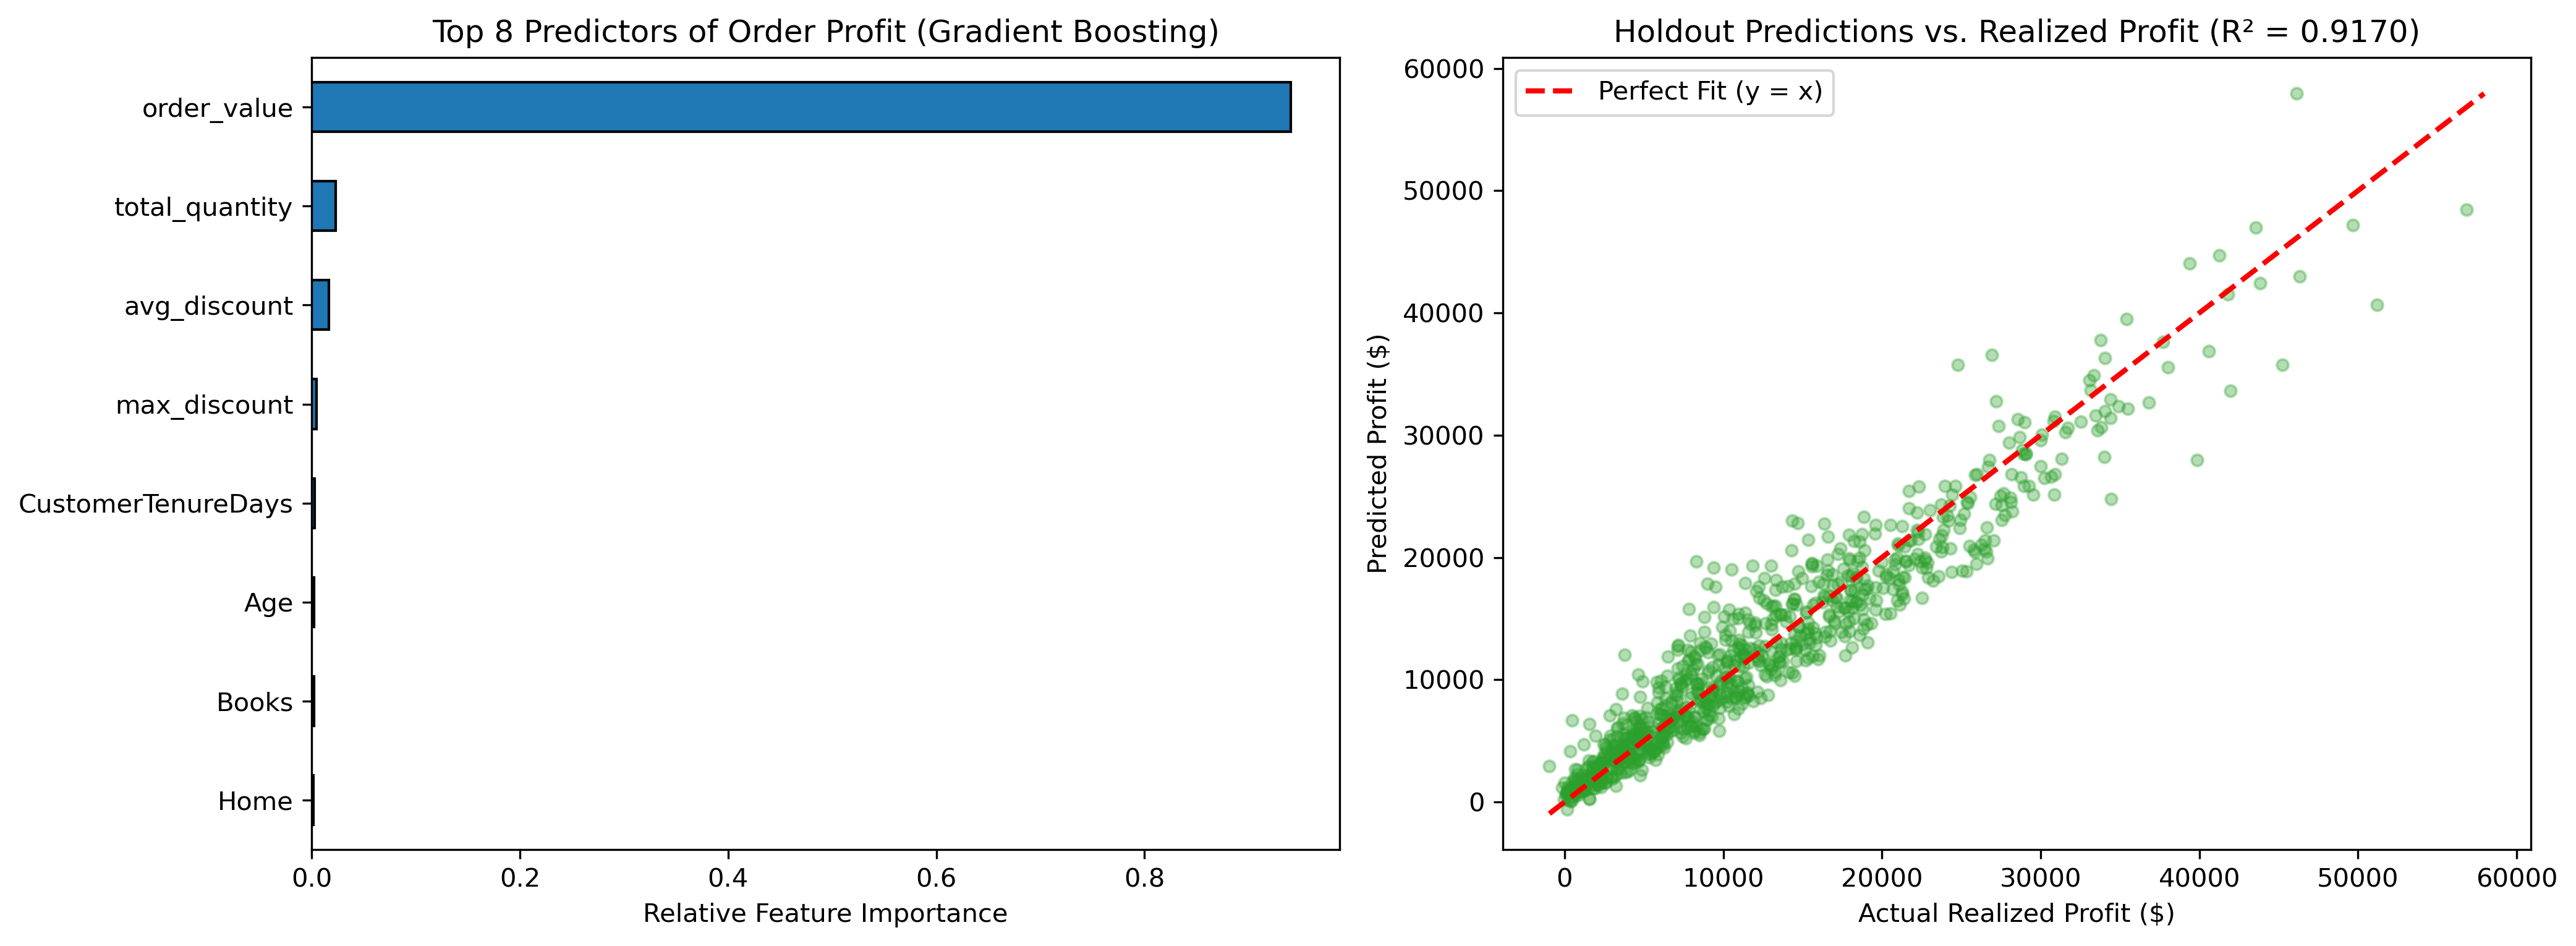


Top 8 Feature Importances:


order_value           0.940539
total_quantity        0.023265
avg_discount          0.016633
max_discount          0.004941
CustomerTenureDays    0.003235
Age                   0.002514
Books                 0.002083
Home                  0.001889
dtype: float64

In [4]:
gb_model = fitted_models['Gradient Boosting']
feat_imp = pd.Series(gb_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2), dpi=300)

# Feature Importance Bar Plot
feat_imp.head(8).plot(kind='barh', ax=ax1, color='#1f77b4', edgecolor='black')
ax1.set_title("Top 8 Predictors of Order Profit (Gradient Boosting)")
ax1.set_xlabel("Relative Feature Importance")
ax1.invert_yaxis()

# Actual vs Predicted Profit
gb_preds = gb_model.predict(X_test)
ax2.scatter(y_test, gb_preds, alpha=0.35, color='#2ca02c', s=20)
min_val = min(y_test.min(), gb_preds.min())
max_val = max(y_test.max(), gb_preds.max())
ax2.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Perfect Fit (y = x)')
ax2.set_title(f"Holdout Predictions vs. Realized Profit (R² = {r2_score(y_test, gb_preds):.4f})")
ax2.set_xlabel("Actual Realized Profit ($)")
ax2.set_ylabel("Predicted Profit ($)")
ax2.legend()

plt.tight_layout()
plt.savefig('reports/figures/05_model_diagnostics.png', bbox_inches='tight')
plt.show()

print("\nTop 8 Feature Importances:")
display(feat_imp.head(8))